# IBM HR Attrition
### *Predicting and Explaining Employee Turnover*

---
* **Project Type:** Portfolio Project  
* **Author:** Arjun Kumar  
* **Time Invested:** 32 Hours  
* **Note:** This notebook is NOT generated by A.I.
---

## 1. Business Framing

**A VP of HR is trying to decide where to focus a limited retention budget. If we can identify which employees are at highest risk of leaving — and why — she can target interventions (raises, role changes, manager check-ins) 
at the segments where they'll have the most impact, instead of spreading resources thin across the whole company.**

**Business questions this project should answer:**
1. Which employee segments (by role, department, tenure, or other factors) have the highest attrition risk?
2. What are the strongest, most explainable drivers of attrition — and do they point to anything the company can actually act on (e.g., compensation, overtime, commute distance)?
3. If we focus retention efforts on the highest-risk segment, roughly what could that be worth in reduced turnover cost?

In [1]:
import pandas as pd
import numpy as np

#visualization
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import confusion_matrix, accuracy_score, classification_report, roc_auc_score
from sklearn.metrics import precision_recall_curve,roc_curve,recall_score,precision_score, f1_score, roc_auc_score
from sklearn.model_selection import GridSearchCV

import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

## 2. Exploratory Data Analysis (EDA)

### 2.1 Load Data & Basic Structure

In [2]:
df = pd.read_csv('res/HR-Em.csv')
df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition                 1470 non-null   object
 2   BusinessTravel            1470 non-null   object
 3   DailyRate                 1470 non-null   int64 
 4   Department                1470 non-null   object
 5   DistanceFromHome          1470 non-null   int64 
 6   Education                 1470 non-null   int64 
 7   EducationField            1470 non-null   object
 8   EmployeeCount             1470 non-null   int64 
 9   EmployeeNumber            1470 non-null   int64 
 10  EnvironmentSatisfaction   1470 non-null   int64 
 11  Gender                    1470 non-null   object
 12  HourlyRate                1470 non-null   int64 
 13  JobInvolvement            1470 non-null   int64 
 14  JobLevel                

In [4]:
df.isnull().sum()

Age                         0
Attrition                   0
BusinessTravel              0
DailyRate                   0
Department                  0
DistanceFromHome            0
Education                   0
EducationField              0
EmployeeCount               0
EmployeeNumber              0
EnvironmentSatisfaction     0
Gender                      0
HourlyRate                  0
JobInvolvement              0
JobLevel                    0
JobRole                     0
JobSatisfaction             0
MaritalStatus               0
MonthlyIncome               0
MonthlyRate                 0
NumCompaniesWorked          0
Over18                      0
OverTime                    0
PercentSalaryHike           0
PerformanceRating           0
RelationshipSatisfaction    0
StandardHours               0
StockOptionLevel            0
TotalWorkingYears           0
TrainingTimesLastYear       0
WorkLifeBalance             0
YearsAtCompany              0
YearsInCurrentRole          0
YearsSince

In [5]:
df.nunique()

Age                           43
Attrition                      2
BusinessTravel                 3
DailyRate                    886
Department                     3
DistanceFromHome              29
Education                      5
EducationField                 6
EmployeeCount                  1
EmployeeNumber              1470
EnvironmentSatisfaction        4
Gender                         2
HourlyRate                    71
JobInvolvement                 4
JobLevel                       5
JobRole                        9
JobSatisfaction                4
MaritalStatus                  3
MonthlyIncome               1349
MonthlyRate                 1427
NumCompaniesWorked            10
Over18                         1
OverTime                       2
PercentSalaryHike             15
PerformanceRating              2
RelationshipSatisfaction       4
StandardHours                  1
StockOptionLevel               4
TotalWorkingYears             40
TrainingTimesLastYear          7
WorkLifeBa

In [6]:
numeric_cols = df.select_dtypes(include=['int64', 'float64']).columns
unique_counts = df[numeric_cols].nunique().sort_values()

discrete_num_cols = unique_counts[unique_counts <= 10].index      # numeric but few values -> treat as ordinal/categorical
continuous_cols = unique_counts[unique_counts > 10].index          # genuinely continuous



categorical_cols = df.select_dtypes(exclude=['int64', 'float64']).columns  # true string/object categoricals

# final groupings 
all_categorical = list(categorical_cols) + list(discrete_num_cols)
all_continuous = list(continuous_cols)


#stil need to remove ids, zero variation variables from the variables lists.
cont_cols_to_remove = ['HourlyRate', 'DailyRate','MonthlyRate' ,'EmployeeNumber'] #remove zero variation variables and noise variables hourly rate, daily etc and use only monthly income to represent compensation
cat_cols_to_remove = ['Attrition' , 'Over18' , 'EmployeeCount' , 'StandardHours'] #remove outcome variable, and constant categorical / numerical variables.

all_continuous = [c for c in all_continuous if c not in cont_cols_to_remove]
all_categorical = [c for c in all_categorical if c not in cat_cols_to_remove]

nominal = ['Department','EducationField','Gender',
           'JobRole','MaritalStatus', 'OverTime']  #label variables representing different categories

ordinal = ['BusinessTravel' , 'PerformanceRating','RelationshipSatisfaction',
           'EnvironmentSatisfaction','WorkLifeBalance','JobInvolvement',
           'StockOptionLevel', 'JobSatisfaction','JobLevel','Education']  #all the ratings are essentially ordinal

discrete = ['TrainingTimesLastYear','NumCompaniesWorked'] #numeric variables which has less variance. (technically continous variable)

### 2.2 Class Balance (Attrition)

In [7]:
df['Attrition'].value_counts(normalize=True) #normalize to find the proportion of the classes than absolute values for better comparison.

Attrition
No     0.838776
Yes    0.161224
Name: proportion, dtype: float64

**Takeaway :** 
1. Roughly 16% is the overall average attrition rate (can be used as benchmark to compare if any subgroup consists of significantly higher rate to find at risk for attrition)
2. Class imbalance suggests normal accuracy measures would not be sufficient to interpret the model results, Use ROC-AUC , Precision , Sensitivity and Specificity during classification modelling.

### 2.3 Univariate Distributions

#### 2.3.1 continuous variables distribution

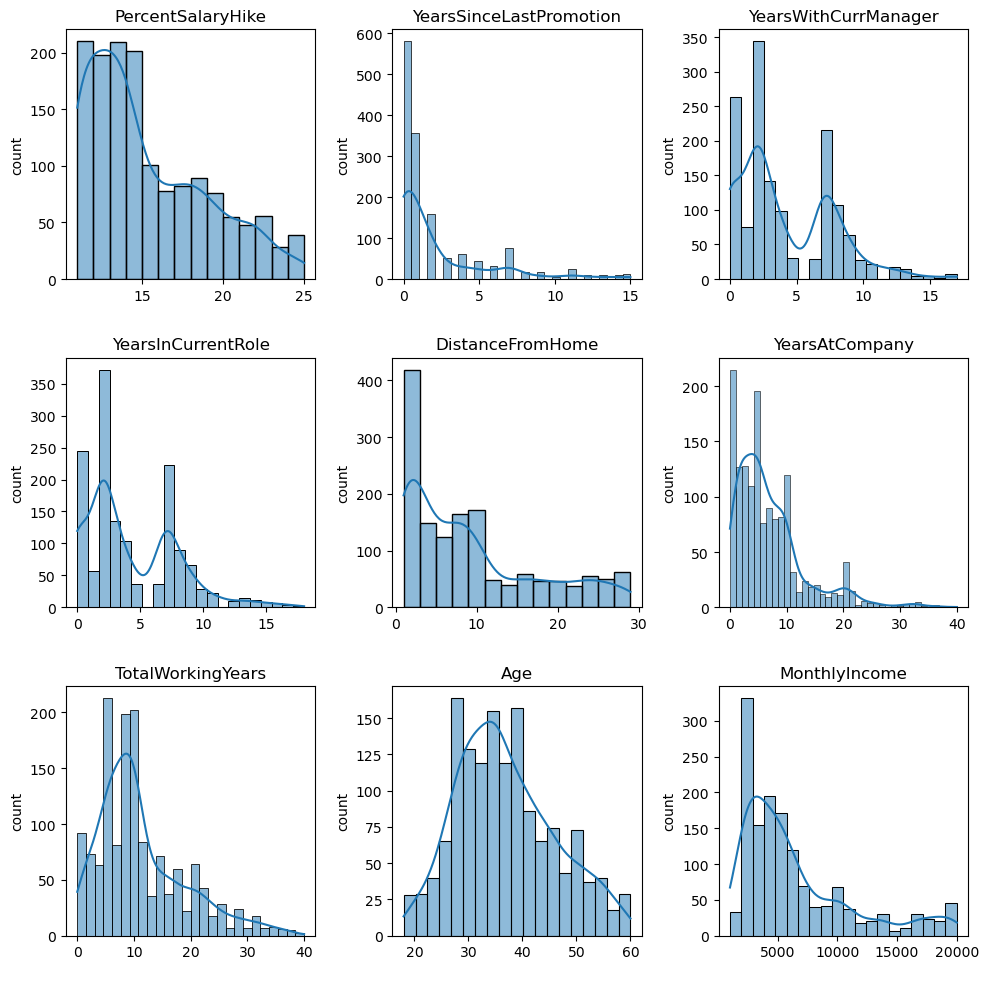

In [8]:
#total 9 continuous features so created a 3x3 grid of subplots
fig, axes = plt.subplots(nrows=3, ncols=3, figsize=(10, 10))
axes = axes.flatten() #flattens the axes so that it changes from a 2d list to a 1d list to loop through each axes using just i. 


for i , col in enumerate(all_continuous):
    sns.histplot(df[col], ax = axes[i], kde = True )
    axes[i].set_title(col)
    axes[i].set_xlabel(' ')
    axes[i].set_ylabel('count')

plt.tight_layout()

**Takeaway:** 

1. Severe right skew across Experience and compensation

   **MonthlyIncome**: Extremely right-skewed with a massive spike under $5,000(worth checking if it is concentrated under specific job role or level) and a long tail extending to 20,000 (executive salaries).

   **YearsAtCompany & TotalWorkingYears**: Both show strong right skew—most employees are in their first 10 years of career/company tenure, with steep drop-offs after 10 years.

   **PercentSalaryHike & DistanceFromHome**: Heavily concentrated at the lower ends (11–15% hikes and 1–10 miles distance).

   

3. Only near normal feature

   

   **Age**: Roughly symmetric bell curve centered around 35 years old.

   

5. possible correlation & twin structural spikes

   **YearsInCurrentRole & YearsWithCurerntManager**:  indicates company policy rhythms—employees frequently switch roles or managers at 2-year and 7-year internal evaluation milestones. likely share a very high correlation coefficient

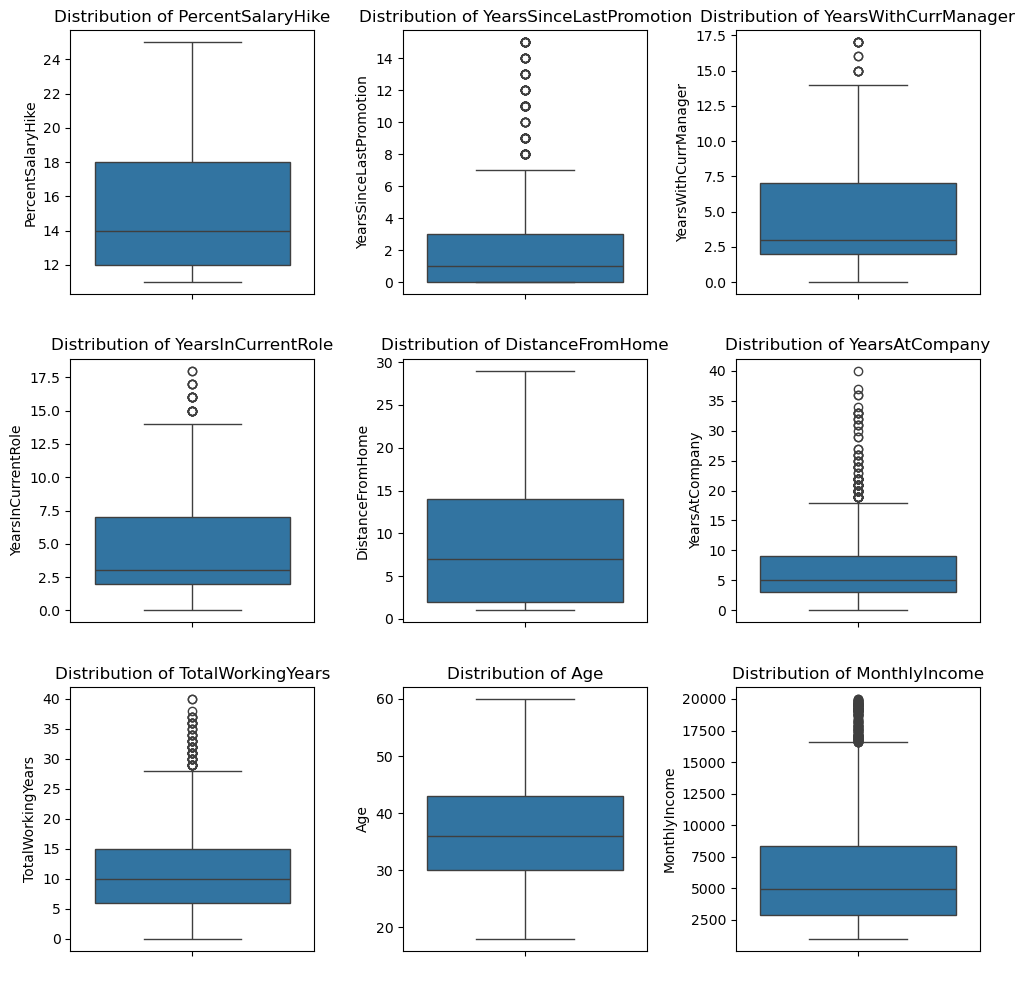

In [9]:
fig, axes = plt.subplots(nrows=3, ncols=3, figsize=(10, 10))
axes = axes.flatten()


for i , col in enumerate(all_continuous):
    sns.boxplot(df[col], ax = axes[i])
    axes[i].set_title(f'Distribution of {col}')
    axes[i].set_xlabel(' ')

plt.tight_layout()

#### 2.3.2 categorical variables distribution

    nominal variables distribution

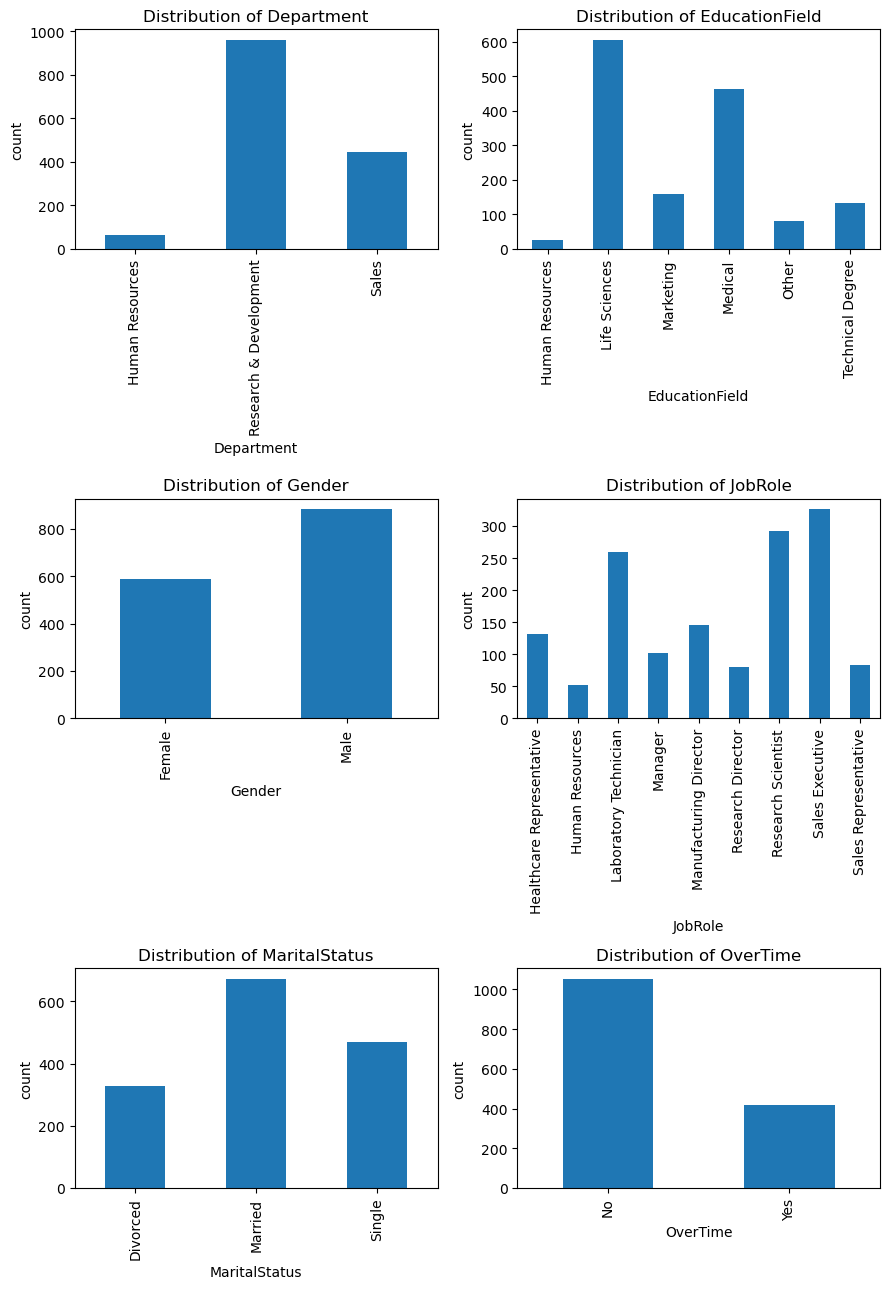

In [10]:
fig, axes = plt.subplots(nrows=3, ncols=2, figsize=(9, 13))  # adjust nrows to fit len(nominal)
axes = axes.flatten()

for i, col in enumerate(nominal):
    df[col].value_counts().sort_index().plot(kind='bar', ax=axes[i])
    axes[i].tick_params(axis='x', rotation=90)
    axes[i].set_title(f'Distribution of {col}')
    axes[i].set_ylabel('count')



plt.tight_layout()



    ordinal variables

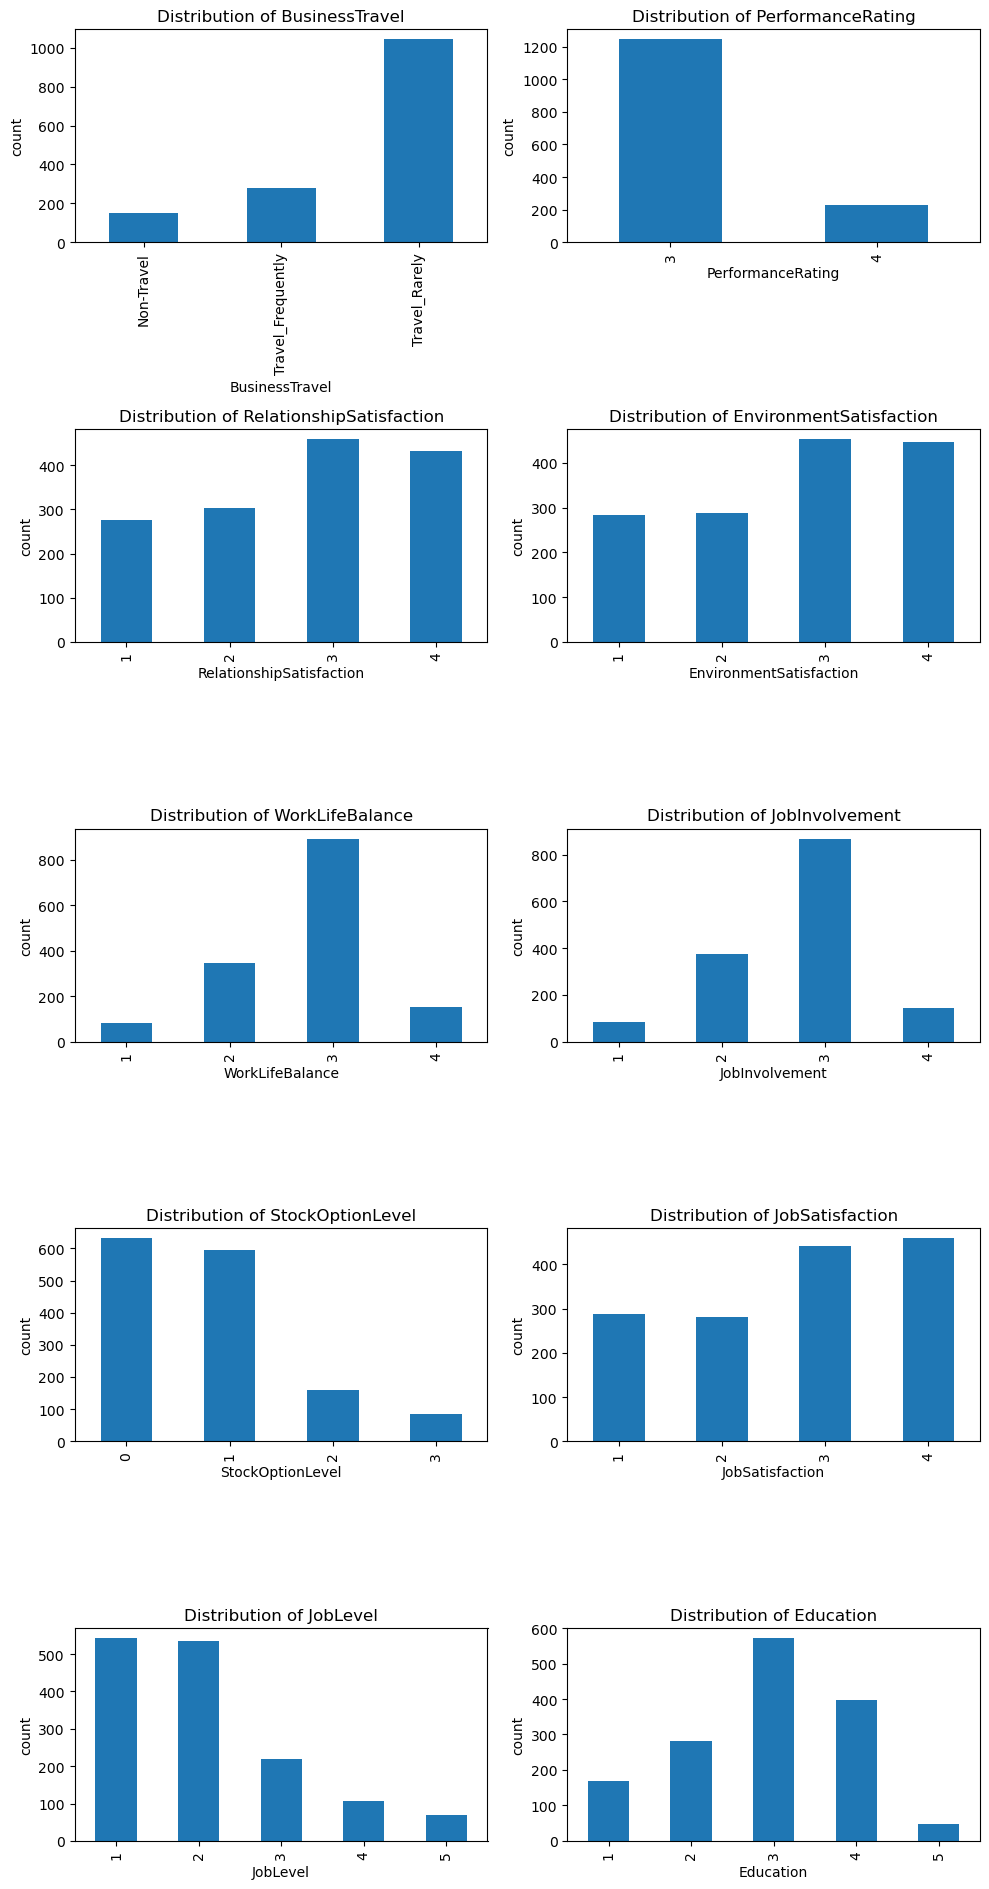

In [11]:
fig, axes = plt.subplots(nrows=5, ncols=2, figsize=(10, 19))  # adjust nrows to fit len(ordinal)
axes = axes.flatten()

for i, col in enumerate(ordinal):
    df[col].value_counts().sort_index().plot(kind='bar', ax=axes[i])
    axes[i].tick_params(axis='x', rotation= 90)
    axes[i].set_title(f'Distribution of {col}')
    axes[i].set_ylabel('count')


plt.tight_layout()


    discrete variables

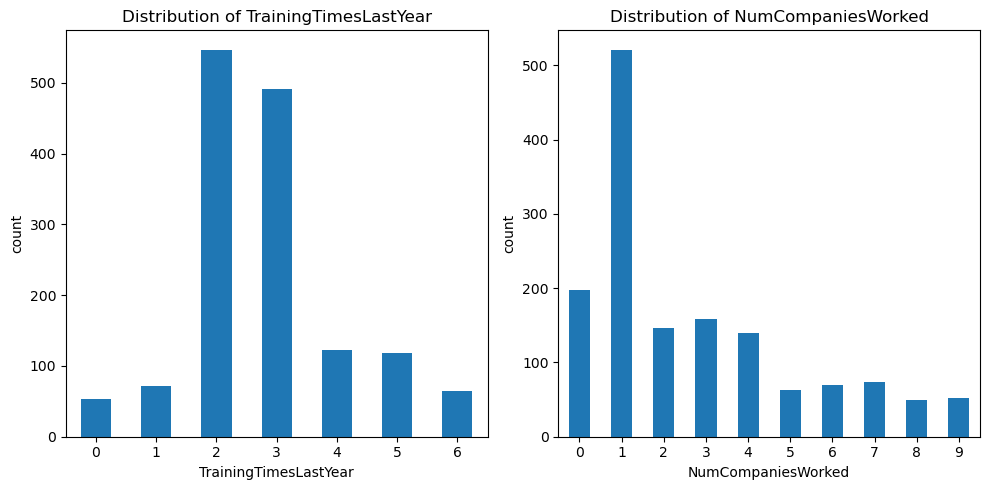

In [12]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(10, 5))  # adjust nrows to fit len(ordinal)
axes = axes.flatten()

for i, col in enumerate(discrete):
    df[col].value_counts().sort_index().plot(kind='bar', ax=axes[i])
    axes[i].tick_params(axis='x', rotation= 0)
    axes[i].set_title(f'Distribution of {col}')
    axes[i].set_ylabel('count')


plt.tight_layout()

### 2.4 Bivariate — Attrition Rate by Category

continous variables

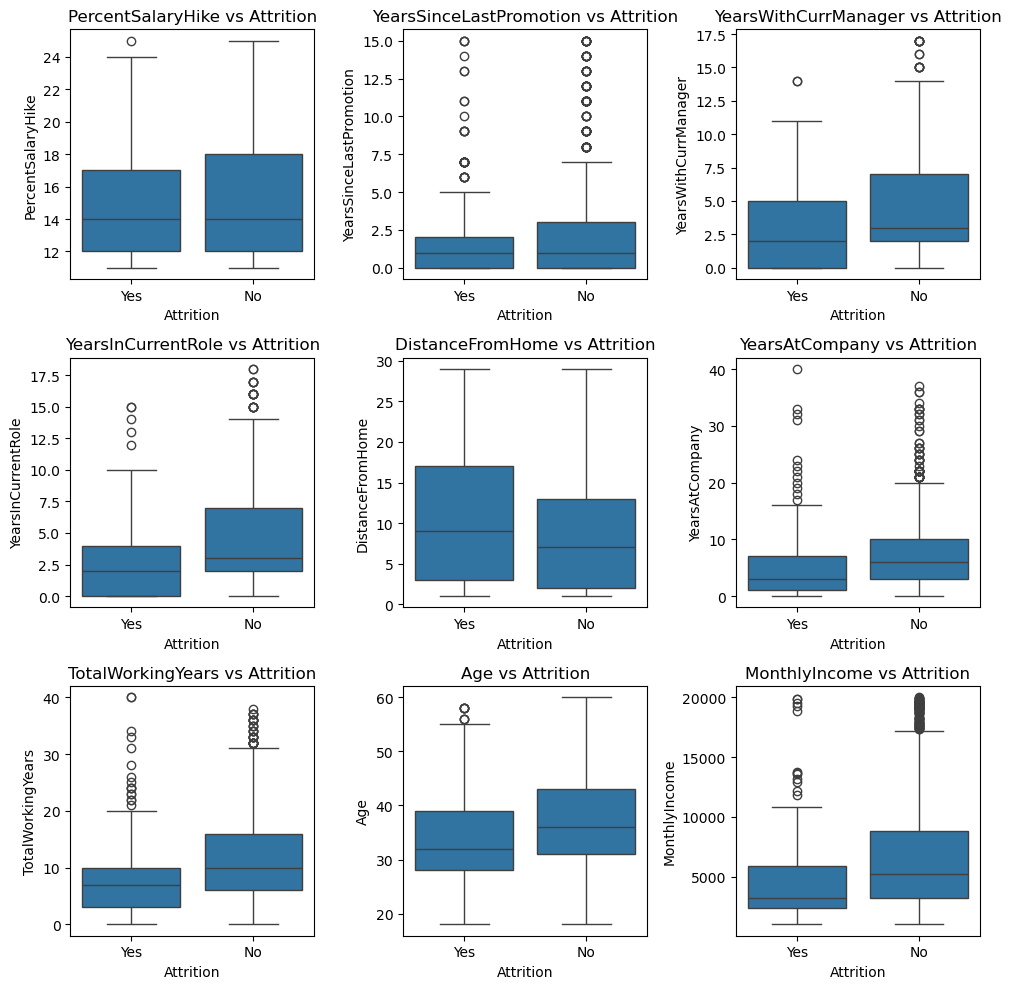

In [13]:
fig, axes = plt.subplots(nrows=3, ncols=3, figsize=(10, 10))
axes = axes.flatten() 

for i, col in enumerate(df[all_continuous]):
    # Use Boxplots for continuous features vs Attrition
    sns.boxplot(data=df, x='Attrition', y=col, ax=axes[i])
    axes[i].set_title(f'{col} vs Attrition')

plt.tight_layout()
plt.show();
    

**Takeaway:** 

- Employee tenure, career experience, age, and compensation are the primary drivers of attrition, while salary increases and commute distance have minimal impact. Employees who leave tend to be younger, less experienced, newer to their current roles, and lower-paid—suggesting junior employees with less organizational stability are at highest risk.

**Discrete Variables**

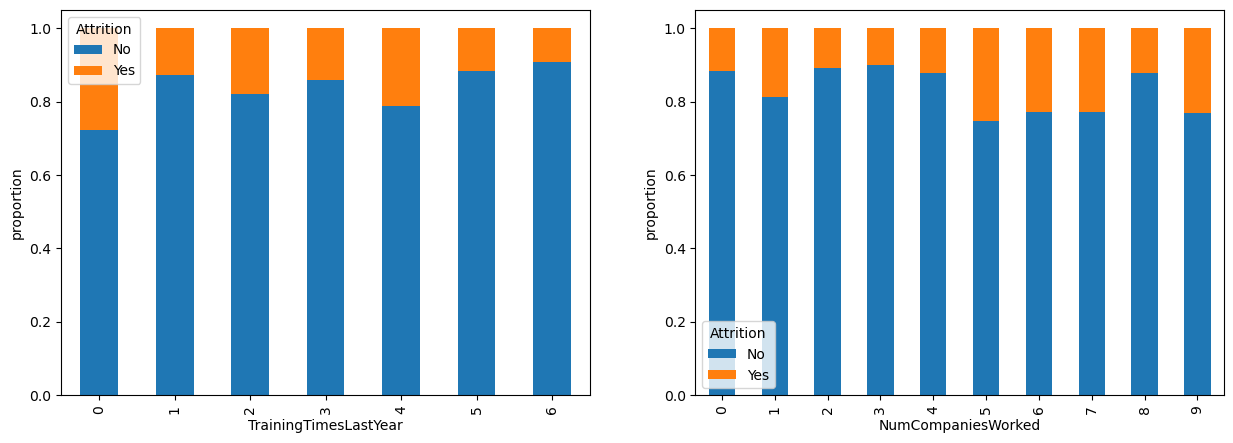

In [14]:
fig, axes = plt.subplots(nrows = 1 , ncols = 2 , figsize = (15,5))

for i, col in enumerate(discrete):   
    pd.crosstab(df[col] , df['Attrition'] , normalize = 'index').plot(kind = 'bar' , stacked = True , ax = axes[i])
    axes[i].set_ylabel('proportion')

**Takeaway:**

1. TrainingTimesLastYear : employees with 0 training provided last year shows a higher attrition rate roughly 28% compared to those receiving 2 - 6 training, 10% - 15%
2. NumCompaniesWorked : non linear trend, higher attrition (19%) among employees who has worked in 1 company prior and an attrition rate of (20% - 25%) among job hoppers who has worked in over 5 companies. but lower risk (10%) for those with 2 - 4 switches

**Categorical - ordinal variables**

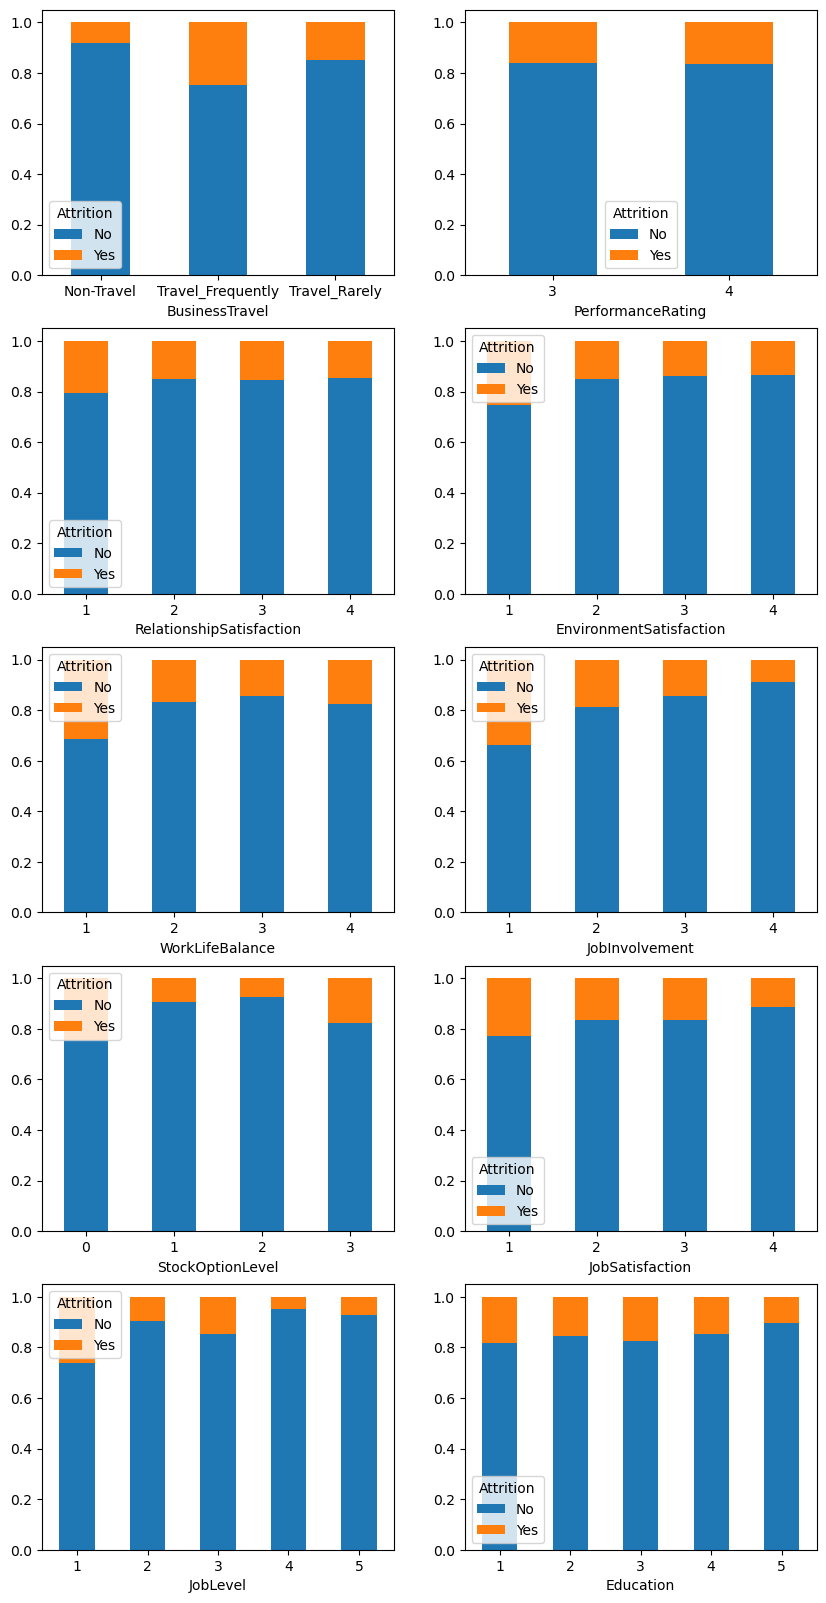

In [15]:
fig, axes = plt.subplots(nrows = 5 , ncols = 2 , figsize = (10,20))
axes = axes.flatten() 

for i, col in enumerate(ordinal):   
    pd.crosstab(df[col] , df['Attrition'] , normalize = 'index').plot(kind = 'bar' , stacked = True , ax = axes[i])
    axes[i].tick_params(axis = 'x' , rotation = 0)

**Takeaway:** 
    
1. businessTravel : seems to be a linear pattern for attrition rating among business travellers.
2. performanceRating : less variation 
3. relationshipSatisfaction : slight/less variation
4. environmentSatisfacotion : employees at a lower environment (level 1) is at roughly 2 times more risk of attrition than all other environment.
5. workLifeBalance : attrition rate looks to be higher among ratings of 1 with around 30% attrition rate.
6. jobInvolvement : linear patter in attrition rate from roughly 35% at ratings of 1 and a sudden jump of only 20% attrition rate for ratings of 2. job involvement could be a 
7. StockOptionLevel : Stock options are a significant retention factor—employees with no stock options have ~2-3x higher attrition than those with even minimal stock options (Level 1+). The benefit plateaus after Level 1
8. jobSatisfaction : Key retention factor, employees at level 1 has a attrition rate of 22% vs employees at level 4, attrition of 10%
9. jobLevel : Entry-level employees (Level 1) have 2-3x higher attrition than mid-level and above. Once employees reach Level 3, attrition stabilizes regardless of further promotion
10. Education : Education level is a weak driver of attrition. While there's a slight improvement at higher education levels (Level 5), the differences are minimal (~18% attrition at Level 1 vs. ~10% at Level 5)

**Categorical - nominal variables**

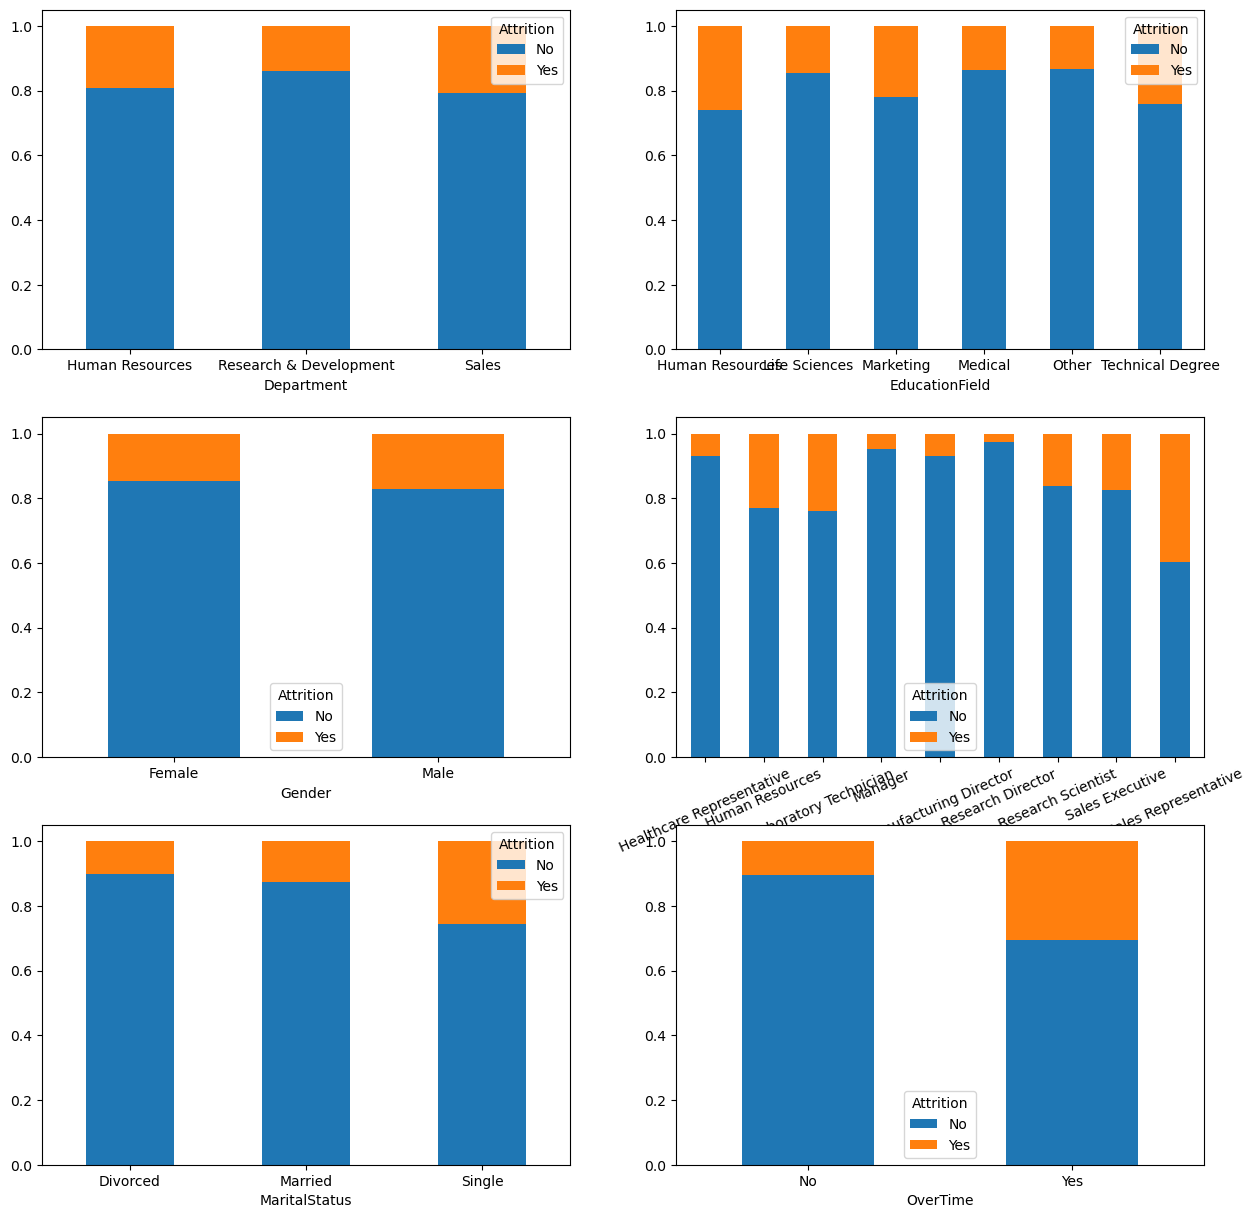

In [16]:
fig, axes = plt.subplots(nrows=3,ncols=2,figsize=(15,15))
axes = axes.flatten()

for i , cols in enumerate(nominal):
    pd.crosstab(df[cols] , df['Attrition'] , normalize = 'index').plot(kind = 'bar' , stacked = True, ax = axes[i])
    axes[i].tick_params(axis = 'x' , rotation = 0)
    if cols == 'JobRole':
        axes[i].tick_params(axis = 'x' , rotation = 24)

### 2.5 Correlation Check (Numeric Predictors)

In [17]:
df[all_continuous].corr()

,PercentSalaryHike,YearsSinceLastPromotion,YearsWithCurrManager,YearsInCurrentRole,DistanceFromHome,YearsAtCompany,TotalWorkingYears,Age,MonthlyIncome
PercentSalaryHike,1.000000,-0.022154,-0.011985,-0.001520,0.040235,-0.035991,-0.020608,0.003634,-0.027269
YearsSinceLastPromotion,-0.022154,1.000000,0.510224,0.548056,0.010029,0.618409,0.404858,0.216513,0.344978
YearsWithCurrManager,-0.011985,0.510224,1.000000,0.714365,0.014406,0.769212,0.459188,0.202089,0.344079
YearsInCurrentRole,-0.001520,0.548056,0.714365,1.000000,0.018845,0.758754,0.460365,0.212901,0.363818
DistanceFromHome,0.040235,0.010029,0.014406,0.018845,1.000000,0.009508,0.004628,-0.001686,-0.017014
YearsAtCompany,-0.035991,0.618409,0.769212,0.758754,0.009508,1.000000,0.628133,0.311309,0.514285
TotalWorkingYears,-0.020608,0.404858,0.459188,0.460365,0.004628,0.628133,1.000000,0.680381,0.772893
Age,0.003634,0.216513,0.202089,0.212901,-0.001686,0.311309,0.680381,1.000000,0.497855
MonthlyIncome,-0.027269,0.344978,0.344079,0.363818,-0.017014,0.514285,0.772893,0.497855,1.000000


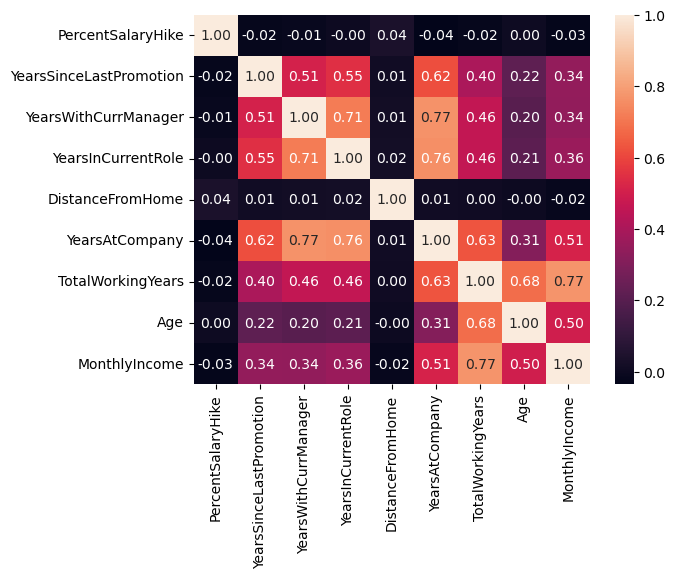

In [18]:
sns.heatmap(df[all_continuous].corr(), annot = True , fmt = '.2f');

**Takeaway:** 

YearsAtCompany & YearsInCurrentRole has a correlation of 0.76, worth checking for possible multicollinearity.

**EDA Summary**

**Candidate insights so far:**

1. Employee tenure seems interesting to be a real driver for attrition rates.  
- Variables : TotalWorkingYears,YearsAtCompany,YearsInCurrentRole                 
    
2. Employees who serve overtime has an attrition rate 3 times more than that of the employees who has not served overtime
- Variables : OverTime
       
3. Turnover varies drastically by position, with Sales Representatives experiencing the highest attrition rate at ~40%, followed by Laboratory Technicians and HR roles at ~23%. Conversely, leadership roles like Managers and Directors show exceptional stability, keeping turnover under 10% . 
- Variables : JobRole

4. Employees who travel more frequently than non-business travellers tend to have an attrition rate roughly 3 times higher 

    

**Note:** a variable that looks flat here may still matter once other variables are controlled for in the model (suppressor effect) — will keep in mind to not rule anything out just yet._

## 3. Data Cleaning & Feature Prep

### 3.1 Handle Missing Values

In [19]:
df.isna().sum().any()

np.False_

### 3.2 Define Non-Predictive Columns and confirm target encoding

In [20]:
non_pred_cols = ['HourlyRate','DailyRate','MonthlyRate','EmployeeNumber','Over18','EmployeeCount','StandardHours','Attrition'] #Department is dropped to avoid multicollinearity later with JobRole, keeping JobRole so that it has the same but more granual level information of the same

In [21]:
# Attrition Yes/No -> 1/0
df['Attrition'] = df['Attrition'].map({'Yes' : 1 , 'No' : 0})

### 3.3 Encode Categorical Variables

In [22]:
#converting the ordered categorical feature 'Business Travel' into the appropriate dtype
df['BusinessTravel'] = pd.Categorical(df['BusinessTravel'],
                                      categories = ['Non-Travel' , 'Travel_Rarely' , 'Travel_Frequently'],
                                      ordered = True)

df['BusinessTravel'].dtype

CategoricalDtype(categories=['Non-Travel', 'Travel_Rarely', 'Travel_Frequently'], ordered=True, categories_dtype=object)

In [23]:
# pd.get_dummies for nominal; ordinal encoding where real order exists

X = df.drop(columns = non_pred_cols)

#identified binary variables from the nominal variables.
binary_nominal = ['OverTime', 'Gender'] 
one_hot_encode_vars = [item for item in nominal if item not in binary_nominal] #nominal variables for one-hot-encoding

#binary encoding the binary variables from the nominal var list
X['Gender'] = X['Gender'].map({'Male' : 0 , 'Female' : 1})
X['OverTime'] = X['OverTime'].map({'No' : 0, 'Yes' : 1})


# Convert ordered categorical BusinessTravel to integer codes (0, 1, 2)
# This preserves the ordinal relationship: 0=Non-Travel, 1=Travel_Rarely, 2=Travel_Frequently
X['BusinessTravel'] = df['BusinessTravel'].cat.codes

X = pd.get_dummies(X , columns = one_hot_encode_vars , drop_first = True , dtype = int)
y = df['Attrition']

# Verify X is all numeric
print(X.dtypes)

# Verify no missing values
print('\n',X.isnull().sum()) 


Age                                  int64
BusinessTravel                        int8
DistanceFromHome                     int64
Education                            int64
EnvironmentSatisfaction              int64
Gender                               int64
JobInvolvement                       int64
JobLevel                             int64
JobSatisfaction                      int64
MonthlyIncome                        int64
NumCompaniesWorked                   int64
OverTime                             int64
PercentSalaryHike                    int64
PerformanceRating                    int64
RelationshipSatisfaction             int64
StockOptionLevel                     int64
TotalWorkingYears                    int64
TrainingTimesLastYear                int64
WorkLifeBalance                      int64
YearsAtCompany                       int64
YearsInCurrentRole                   int64
YearsSinceLastPromotion              int64
YearsWithCurrManager                 int64
Department_

In [24]:
X.columns

Index(['Age', 'BusinessTravel', 'DistanceFromHome', 'Education',
       'EnvironmentSatisfaction', 'Gender', 'JobInvolvement', 'JobLevel',
       'JobSatisfaction', 'MonthlyIncome', 'NumCompaniesWorked', 'OverTime',
       'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction',
       'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear',
       'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole',
       'YearsSinceLastPromotion', 'YearsWithCurrManager',
       'Department_Research & Development', 'Department_Sales',
       'EducationField_Life Sciences', 'EducationField_Marketing',
       'EducationField_Medical', 'EducationField_Other',
       'EducationField_Technical Degree', 'JobRole_Human Resources',
       'JobRole_Laboratory Technician', 'JobRole_Manager',
       'JobRole_Manufacturing Director', 'JobRole_Research Director',
       'JobRole_Research Scientist', 'JobRole_Sales Executive',
       'JobRole_Sales Representative', 'MaritalStatus_Marrie

### 3.4 Train/Test Split and standard scaling

In [25]:
#stratify=y for making sure the train and test split has the same proportion of attrtions to counter the rare class problem.
def split_and_standardize(X, y, job_levels=None):
    #job level is not used for final modelling but is still required for cost-based threshold analysis. hence, the split.
    if job_levels is not None:
        # Split with job_levels array
        X_train, X_test, y_train, y_test, jl_train, jl_test = train_test_split(
            X, y, job_levels, test_size=0.2, random_state=1, stratify=y
        )
    else:
        # Standard split without extra metadata
        X_train, X_test, y_train, y_test = train_test_split(
            X, y, test_size=0.2, random_state=1, stratify=y
        )
        jl_train, jl_test = None, None

    scaler = StandardScaler()
    X_train_std = scaler.fit_transform(X_train) #fit_transform stores the stats, mean , variance and scale(standard deviation) for each of the column and standardizes the given set as well.
    X_test_std = scaler.transform(X_test) #scaler.transform standardizes the given set of data using the stored mean and std.

    return X_train_std, X_test_std, y_train, y_test, scaler, jl_train, jl_test

## 4. Modeling

**priorities for modelling**

1. priority for the model is to catch more leavers even if it leads to higher flagging of false positive instances (prioritize higher recall opposed to precision)
2. precision can comparitively be flexible in our case as false alarms does not contribute to a higher loss than missing true alarms.

### 4.1 Baseline Logistic Regression

In [26]:
X_train_std, X_test_std, y_train, y_test , *_ = split_and_standardize(X,y) #no use for scaler or additional jobLevel feature for baseline modelling.

logit_reg = LogisticRegression(class_weight = 'balanced')
logit_reg.fit(X_train_std, y_train)


,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,'balanced'
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


### 4.2 Evaluation On Logistic Regression

In [27]:
def evaluate(model , X_train , X_test , y_train , y_test):
   
    y_train_predicted = model.predict(X_train)
    y_test_predicted = model.predict(X_test)

    #evaluation on training set
    print('==========MODEL EVALUATION ON TRAINING SET=================\n')
    train_cls_report = pd.DataFrame(classification_report(y_train , y_train_predicted, output_dict = True))
    print(f'Confusion Matrix\n{confusion_matrix(y_train , y_train_predicted)}\n')
    print(f'Accuracy\n{accuracy_score(y_train , y_train_predicted):.4f}\n')
    print(f'Classification Report\n{train_cls_report}\n')

    #evaluation on test set
    print('==========MODEL EVALUATION ON TEST SET=================\n')
    test_cls_report = pd.DataFrame(classification_report(y_test , y_test_predicted , output_dict = True))
    print(f'Confusion Matrix\n{confusion_matrix(y_test , y_test_predicted)}\n')
    print(f'Accuracy\n{accuracy_score(y_test , y_test_predicted):.4f}\n')
    print(f'Classfication Report\n{test_cls_report}\n')


In [28]:
evaluate(logit_reg , X_train_std , X_test_std , y_train , y_test)

==========MODEL EVALUATION ON TRAINING SET=================

Confusion Matrix
[[755 231]
 [ 37 153]]

Accuracy
0.7721

Classification Report
                    0           1  accuracy    macro avg  weighted avg
precision    0.953283    0.398438  0.772109     0.675860      0.863639
recall       0.765720    0.805263  0.772109     0.785492      0.772109
f1-score     0.849269    0.533101  0.772109     0.691185      0.798187
support    986.000000  190.000000  0.772109  1176.000000   1176.000000

==========MODEL EVALUATION ON TEST SET=================

Confusion Matrix
[[178  69]
 [ 10  37]]

Accuracy
0.7313

Classfication Report
                    0          1  accuracy   macro avg  weighted avg
precision    0.946809   0.349057  0.731293    0.647933      0.851250
recall       0.720648   0.787234  0.731293    0.753941      0.731293
f1-score     0.818391   0.483660  0.731293    0.651025      0.764879
support    247.000000  47.000000  0.731293  294.000000    294.000000



**NOTES:** 
  
1. (precision - out of all employees that were predicted to leave, what percent of them actually left formula = (TP/TP+FP))    
2. (recall - out of all the employees that actually left, how much was the model able to catch? formula = (TP/TP+FN))

**Takeaway:** 

1. Accuracy drop about 4% points from the training to test data.
2. Class 1 precision drop from 39.8% to 34.9%. 
3. Class 1 recall drop from 80.5% to 78.7%
4. Class 1 f1-score drop from 53.3% to 48.3% 

**Summary:** Overall the baseline logistic model shows no significant signs for overfitting and demonstrates strong generalization among the test set.
    

### 4.3 Second Model (Random Forest)

In [29]:
# compare performance to baseline
rf_model = RandomForestClassifier(n_estimators=100,
                                  max_depth=10,
                                  random_state=42,
                                  class_weight='balanced')  # shouldve used min_impurity_decrease to get a better performance check of the model. 004 maybe.

# Use X_train_std directly
rf_model.fit(X_train_std, y_train)

# Evaluate
rf_test_pred = rf_model.predict(X_test_std)

evaluate(rf_model, X_train_std, X_test_std, y_train , y_test)


==========MODEL EVALUATION ON TRAINING SET=================

Confusion Matrix
[[986   0]
 [  3 187]]

Accuracy
0.9974

Classification Report
                    0           1  accuracy    macro avg  weighted avg
precision    0.996967    1.000000  0.997449     0.998483      0.997457
recall       1.000000    0.984211  0.997449     0.992105      0.997449
f1-score     0.998481    0.992042  0.997449     0.995262      0.997441
support    986.000000  190.000000  0.997449  1176.000000   1176.000000

==========MODEL EVALUATION ON TEST SET=================

Confusion Matrix
[[243   4]
 [ 37  10]]

Accuracy
0.8605

Classfication Report
                    0          1  accuracy   macro avg  weighted avg
precision    0.867857   0.714286  0.860544    0.791071      0.843307
recall       0.983806   0.212766  0.860544    0.598286      0.860544
f1-score     0.922201   0.327869  0.860544    0.625035      0.827189
support    247.000000  47.000000  0.860544  294.000000    294.000000




**Takeaway:** 

1. Accuracy drop about 13% points from the training(99.7%) to test data(86.1%).
2. Class 1 precision drop from 100% to 71.4%. 
3. Class 1 recall drop from 98.4% to 21.2%
4. Class 1 f1-score drop from 99.2% to 32.7% 

**Summary:** model shows weak generalization and significant signs of overfitting and memorization of training data. Moreover while implemented on the test data, recall and f1-score drops severely by about 77% and 66% respectively. Low recall on the test data suggests that the model fails to catch employees at real attrition risk.

### 4.4 Final Model Choice

In [30]:
def models_comparison(model1 , model2 , X_test , y_test):

    # Compare both models on test set (Class 1 metrics ONLY)
    comparison = pd.DataFrame({'Metric': ['Accuracy', 'Recall (Class 1)', 'Precision (Class 1)', 'F1-Score', 'ROC-AUC'],
    #metrics from the first baseline model
    type(model1).__name__: [  #extracted model name from the model to keep function dynamic
        model1.score(X_test, y_test),
        recall_score(y_test, model1.predict(X_test)),
        precision_score(y_test, model1.predict(X_test)),
        f1_score(y_test, model1.predict(X_test)),
        roc_auc_score(y_test, model1.predict_proba(X_test)[:, 1])
    ],
    #metrics from the second baseline model, 
    type(model2).__name__: [ 
        model2.score(X_test, y_test),
        recall_score(y_test, model2.predict(X_test)),
        precision_score(y_test, model2.predict(X_test)),
        f1_score(y_test, model2.predict(X_test)),
        roc_auc_score(y_test, model2.predict_proba(X_test)[:, 1])
    ]
    })

    return comparison

In [31]:
models_comparison( rf_model , logit_reg , X_test_std , y_test) 

,Metric,RandomForestClassifier,LogisticRegression
0,Accuracy,0.860544,0.731293
1,Recall (Class 1),0.212766,0.787234
2,Precision (Class 1),0.714286,0.349057
3,F1-Score,0.327869,0.483660
4,ROC-AUC,0.846585,0.833233



**Model Choice:** 

    Comparing on the basis of metrics from the two baseline models generated. Moving forward with Logistic Regression seems to be the more reasonable choice over Random Forest.

**Reasons:**

1. Strong overfitting pattern noticeable in the baseline Random Forest Model, an accuracy of 99.7% dropped down to 86% 

2. for the prioritized evaluation metric decided prior to modelling (recall) Train metrics for the baseline RF model showed a suspiciously high recall of 98.4% where as on the unseen data, it drastically reduces down to 21.27%. suggesting training data memorization / high model complexity, considerably because of the sample size used is expected to contribute to data memorization for RF models in general.

3. Much more defined generalization between the train and test data shown for the logistic regression model where metrics seems to not vary as much where as in the RF model the evaluation metrics from the training data and the test data seem to vary drasctically.

4. Baseline Logistic Regression model on the standardized test data has a higher recall rate of 78.72% identified although the precision is only 34.90%, it could be tackled by increasing the classification threshold to catch lesser False Positives.

5. The known issue of multicollinearity identified during EDA, affects the metrics of Logistic Regression model more than it does for Random Forest. therefore that suggests the already comparatively better metrics on the baseline logistic regression model could further be improved by optimizing the model to penalize correlated variables which would reduce/remove the effect of multicollinearity and possibly improve results.

6. More importantly, to align more with the goal of not just prediction but also extracting business insights, Logistic regression's interpretable odds ratio fits better overall.



### 4.5 Model Optimization

  
**Note:** During the baseline model evaluation, I discovered significant multicollinearity issues that should have been identified pre-modelling. For completeness, I address them now before finalizing the model.

#### 4.5.1 VIF analysis
VIF analysis to detect and tackle known multicollinearity to make odds ratio interpretable for better business insights

In [32]:
def calculate_vif(X):

    #variance_inflation_factor is pre-built to use on sets which already has added constant to it.
    X_const = add_constant(X) #inorder to get the true statistically accurate VIF scores we need to add a constant to the X set.    
    vif_df = pd.DataFrame()
    vif_df['Features'] = X_const.columns
    vif_df['VIF'] = [variance_inflation_factor(X_const , i) for i in range(X_const.shape[1])]
    return vif_df

In [33]:
#VIF scores of the entire unsplit set for comparison
calculate_vif(X).sort_values(by = 'VIF', ascending = False)

,Features,VIF
0,const,418.755412
24,Department_Research & Development,44.010527
25,Department_Sales,43.932000
26,EducationField_Life Sciences,23.985349
28,EducationField_Medical,21.547947
10,MonthlyIncome,18.046961
37,JobRole_Sales Executive,14.673550
8,JobLevel,14.085360
27,EducationField_Marketing,10.830891
30,EducationField_Technical Degree,8.816587


FEATURES TO REMOVE THROUGH VIF

1. Department_     -  removing department by keeping just Jobrole as it explains the same information with comparatively more granular level information of the same.
2. EducationField_ - owns high VIF score can be removed safely as college major carries almost no actionable leverage for HR
3. JobLevel        - Dropping JobLevel will collapse monthlyIncome feature's VIF significantly.
4. TotalWorkingYears - correlated with monthly income, reduces monthlyIncome VIF further.

FEATURES TO REMOVE THROUGH FEATURE ENGINEERING/LOW-VARIANCE/CORRELATION

1. YearsAtCompany - Used to create stagnation ratio
2. YearsInCurrentRole - Used to create stagnation ratio
3. YearsWithCurrManager - correlated with YearsInCurrentRole
4. PerformanceRating - failure to remove pre EDA, has little to no significant variation.

In [34]:
prefixes_to_drop = ('Department_', 'EducationField_')    
cols_to_drop = [col for col in X.columns if col.startswith(prefixes_to_drop)]
cols_to_drop.extend(['JobLevel','YearsAtCompany', 'YearsInCurrentRole', 'YearsWithCurrManager', 'TotalWorkingYears' , 'PerformanceRating'])

pruned_X = X.copy()

pruned_X['StagnationRatio'] = pruned_X['YearsInCurrentRole'] / (pruned_X['YearsAtCompany'] + 1)
pruned_X.drop(columns=cols_to_drop , inplace = True)

In [35]:
calculate_vif(pruned_X).sort_values(by = 'VIF', ascending = False)

,Features,VIF
0,const,133.528956
9,MonthlyIncome,6.400764
23,JobRole_Research Scientist,3.326825
20,JobRole_Manager,3.234725
19,JobRole_Laboratory Technician,3.138647
27,MaritalStatus_Single,3.014394
24,JobRole_Sales Executive,2.768957
22,JobRole_Research Director,2.542372
21,JobRole_Manufacturing Director,1.923026
25,JobRole_Sales Representative,1.898784


All features except for MonthlyIncome are well below VIF score 5. 
Monthly Income is at 8 which sits below the ceiling of 10. Will be keeping this feature, as compensation is vital for business insights.

#### 4.5.2 C-parameter Grid Search

In [36]:
X_train_std, X_test_std, y_train, y_test , *_ = split_and_standardize(pruned_X,y) 

In [37]:
#GridSearchCV to find best C
param_grid = {'C': [0.001, 0.01, 0.1, 1.0, 10.0, 100.0]}

base_logit_reg = LogisticRegression(penalty='l2',
                                    solver='lbfgs',
                                    class_weight='balanced',
                                    max_iter=1000,
                                    random_state=42)

grid_search = GridSearchCV(estimator = base_logit_reg,
                           param_grid = param_grid,
                           cv=5,
                           scoring='average_precision')



grid_search.fit(X_train_std, y_train)
best_c = grid_search.best_params_['C']

best_c

0.01

In [38]:
cv_results = pd.DataFrame(grid_search.cv_results_)
cv_results

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_C,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
0,0.003078,0.002005,0.000762,0.000370,0.001,{'C': 0.001},0.651357,0.469887,0.487453,0.633738,0.759686,0.600424,0.108509,6
1,0.002691,0.001444,0.000755,0.000374,0.010,{'C': 0.01},0.668218,0.520945,0.514991,0.640859,0.767366,0.622476,0.095168,1
2,0.003186,0.001957,0.000790,0.000691,0.100,{'C': 0.1},0.656632,0.477643,0.515056,0.652904,0.758307,0.612108,0.102490,2
3,0.003186,0.001183,0.000449,0.000038,1.000,{'C': 1.0},0.639629,0.461818,0.524751,0.644491,0.752369,0.604612,0.101407,5
4,0.002750,0.001083,0.000747,0.000559,10.000,{'C': 10.0},0.643207,0.457704,0.526488,0.645037,0.752326,0.604952,0.102594,3
5,0.003771,0.001601,0.000733,0.000388,100.000,{'C': 100.0},0.643330,0.457215,0.526899,0.645310,0.751545,0.604860,0.102479,4


In [39]:
cv_results['mean_test_score'].std()

0.007926009827193882

**TAKE AWAY**:
1. C(inverse of regularization) suggests the best C value under the scoring of PR-AUC (Precision,Recall - AUC) from the grid search is 0.01
2. Our main goal isnt just predictibility but also odds ratio interpretebility for business insights, C value of 0.01 pulls the Coefs closer to 1 to heavily penalize variables. which would diminish our ability to interpret reliable odds ratio for each variable.
3. further investigation on the grid search cross-validation results shows that the standard deviation of the mean test score among each of the parameters offer little to no difference(std of 0.0079) on the PR-AUC scoring. This is possibly a positive effect from the prior pruning of multicollinear variables.
4. However there is a known trade-off of leaving possible recall prioritized optimization on the model for keeping odds-ratio interpretability.

**ACTION:**
1. Can safely stick with the default C value of 1 as we have confirmed it has little to no effect on the results but also lets us keep the odds-ratio safe and more interpretable.
2. For optimizing the recall in the model further without sacrificing interpretability, we can conduct a separate threshold optimization instead.

### 4.6 Fit final optimized model

In [40]:
X_train_std, X_test_std, y_train, y_test , scaler, jobLevel_train , jobLevel_test = split_and_standardize(pruned_X,y,X['JobLevel']) #scaler for unstandardizing odds ratio to measure feature impact on attrition interpretability.

In [41]:
[col for col in pruned_X.columns if col.startswith('JobRole_')]

['JobRole_Human Resources',
 'JobRole_Laboratory Technician',
 'JobRole_Manager',
 'JobRole_Manufacturing Director',
 'JobRole_Research Director',
 'JobRole_Research Scientist',
 'JobRole_Sales Executive',
 'JobRole_Sales Representative']

In [42]:
pruned_X

,Age,BusinessTravel,DistanceFromHome,Education,EnvironmentSatisfaction,Gender,JobInvolvement,JobSatisfaction,MonthlyIncome,NumCompaniesWorked,...,JobRole_Laboratory Technician,JobRole_Manager,JobRole_Manufacturing Director,JobRole_Research Director,JobRole_Research Scientist,JobRole_Sales Executive,JobRole_Sales Representative,MaritalStatus_Married,MaritalStatus_Single,StagnationRatio
0,41,1,1,2,2,1,3,4,5993,8,...,0,0,0,0,0,1,0,0,1,0.571429
1,49,2,8,1,3,0,2,2,5130,1,...,0,0,0,0,1,0,0,1,0,0.636364
2,37,1,2,2,4,0,2,3,2090,6,...,1,0,0,0,0,0,0,0,1,0.000000
3,33,2,3,4,4,1,3,3,2909,1,...,0,0,0,0,1,0,0,1,0,0.777778
4,27,1,2,1,1,0,3,2,3468,9,...,1,0,0,0,0,0,0,1,0,0.666667
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1465,36,2,23,2,3,0,4,4,2571,4,...,1,0,0,0,0,0,0,1,0,0.333333
1466,39,1,6,1,4,0,2,1,9991,4,...,0,0,0,0,0,0,0,1,0,0.875000
1467,27,1,4,3,2,0,4,2,6142,1,...,0,0,1,0,0,0,0,1,0,0.285714
1468,49,2,2,3,4,0,2,2,5390,2,...,0,0,0,0,0,1,0,1,0,0.600000


In [43]:
opt_logit_reg = LogisticRegression(class_weight = 'balanced',
                                   solver='lbfgs',
                                   penalty = 'l2',
                                   C = 1) #C = 1(default)

opt_logit_reg.fit(X_train_std , y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1
,fit_intercept,True
,intercept_scaling,1
,class_weight,'balanced'
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [44]:
evaluate(opt_logit_reg , X_train_std , X_test_std , y_train , y_test)

==========MODEL EVALUATION ON TRAINING SET=================

Confusion Matrix
[[761 225]
 [ 40 150]]

Accuracy
0.7747

Classification Report
                    0           1  accuracy    macro avg  weighted avg
precision    0.950062    0.400000   0.77466     0.675031      0.861192
recall       0.771805    0.789474   0.77466     0.780639      0.774660
f1-score     0.851707    0.530973   0.77466     0.691340      0.799888
support    986.000000  190.000000   0.77466  1176.000000   1176.000000

==========MODEL EVALUATION ON TEST SET=================

Confusion Matrix
[[173  74]
 [  8  39]]

Accuracy
0.7211

Classfication Report
                    0          1  accuracy   macro avg  weighted avg
precision    0.955801   0.345133  0.721088    0.650467      0.858177
recall       0.700405   0.829787  0.721088    0.765096      0.721088
f1-score     0.808411   0.487500  0.721088    0.647956      0.757109
support    247.000000  47.000000  0.721088  294.000000    294.000000



### 4.7 Converting Coefs to interpretable Odds Ratio

**early notes:**
1. The coefs produced by the model are in log odds ratio, exponentiate them.
2. features were standardized prior to modelling so coefs and derived odds ratio would represent 1 unit as 1 standard deviation than literal unit.(need to unstandardize them)
3. the unstandardized odds ratio does not translate to impact according to the odds ratio of each variable, unlike the original output from the model.

#### 4.7.1 Standardized coefficient interpretation (for analyzing hierarchy of impact of each feature)

In [45]:
coefficients = opt_logit_reg.coef_[0]
feature_names = pruned_X.columns

# Convert to odds ratios
odds_ratios = np.exp(coefficients)

# Create interpretation table
standardized_OR = pd.DataFrame({ 'Feature': feature_names,
                         'Coefficient': coefficients,
                         'Odds Ratio': odds_ratios}).sort_values(by = 'Odds Ratio', ascending = False) #table containing feature priority hierarchy 

print(standardized_OR)

top_drivers = standardized_OR[:10] 
top_protectors = standardized_OR[::-1][:10]

                           Feature  Coefficient  Odds Ratio
26            MaritalStatus_Single     0.699622    2.012992
10                        OverTime     0.677665    1.969273
18   JobRole_Laboratory Technician     0.517405    1.677668
16         YearsSinceLastPromotion     0.483890    1.622373
23         JobRole_Sales Executive     0.451926    1.571336
24    JobRole_Sales Representative     0.444908    1.560347
1                   BusinessTravel     0.406829    1.502047
25           MaritalStatus_Married     0.361074    1.434869
9               NumCompaniesWorked     0.353736    1.424379
17         JobRole_Human Resources     0.341788    1.407462
2                 DistanceFromHome     0.309508    1.362755
22      JobRole_Research Scientist     0.212149    1.236332
20  JobRole_Manufacturing Director     0.091632    1.095962
3                        Education     0.015906    1.016033
13                StockOptionLevel    -0.068375    0.933910
11               PercentSalaryHike    -0

In [46]:
#filtering out features with meaningful impact to not act on likely random noise.
impactful_features = standardized_OR[(standardized_OR['Odds Ratio'] < 0.85) | (standardized_OR['Odds Ratio'] > 1.20)]
impactful_features

,Feature,Coefficient,Odds Ratio
26,MaritalStatus_Single,0.699622,2.012992
10,OverTime,0.677665,1.969273
18,JobRole_Laboratory Technician,0.517405,1.677668
16,YearsSinceLastPromotion,0.483890,1.622373
23,JobRole_Sales Executive,0.451926,1.571336
24,JobRole_Sales Representative,0.444908,1.560347
1,BusinessTravel,0.406829,1.502047
25,MaritalStatus_Married,0.361074,1.434869
9,NumCompaniesWorked,0.353736,1.424379
17,JobRole_Human Resources,0.341788,1.407462


In [47]:
top_drivers 

,Feature,Coefficient,Odds Ratio
26,MaritalStatus_Single,0.699622,2.012992
10,OverTime,0.677665,1.969273
18,JobRole_Laboratory Technician,0.517405,1.677668
16,YearsSinceLastPromotion,0.483890,1.622373
23,JobRole_Sales Executive,0.451926,1.571336
24,JobRole_Sales Representative,0.444908,1.560347
1,BusinessTravel,0.406829,1.502047
25,MaritalStatus_Married,0.361074,1.434869
9,NumCompaniesWorked,0.353736,1.424379
17,JobRole_Human Resources,0.341788,1.407462


In [48]:
top_protectors

,Feature,Coefficient,Odds Ratio
27,StagnationRatio,-0.525546,0.591232
4,EnvironmentSatisfaction,-0.437239,0.645817
6,JobInvolvement,-0.377981,0.685243
7,JobSatisfaction,-0.348317,0.705875
21,JobRole_Research Director,-0.265649,0.766708
5,Gender,-0.252409,0.776927
14,TrainingTimesLastYear,-0.226561,0.797271
15,WorkLifeBalance,-0.209398,0.811072
0,Age,-0.205019,0.814631
12,RelationshipSatisfaction,-0.202483,0.816701


#### 4.7.2 Unstandardized coefficient interpretation (to measure the actual impact of identified drivers and protective variables for attrition )

In [49]:
coefficients = opt_logit_reg.coef_[0]
feature_stds = scaler.scale_ 

unstd_coefs = coefficients/feature_stds #unstandardizing the standardized coefs produced by the model.
unstd_OR = np.exp(unstd_coefs) #unstandardized odds ratio

feature_names = pruned_X.columns

unstandardized_OR = pd.DataFrame({'Features' : pruned_X.columns,
                       'Unstd_Coef' : unstd_coefs,
                       'Unstd_Odds_ratio' : unstd_OR})

print(unstandardized_OR)

                          Features  Unstd_Coef  Unstd_Odds_ratio
0                              Age   -0.022397          0.977852
1                   BusinessTravel    0.763196          2.145121
2                 DistanceFromHome    0.037274          1.037978
3                        Education    0.015793          1.015918
4          EnvironmentSatisfaction   -0.394352          0.674117
5                           Gender   -0.515858          0.596988
6                   JobInvolvement   -0.525355          0.591345
7                  JobSatisfaction   -0.318332          0.727361
8                    MonthlyIncome   -0.000038          0.999962
9               NumCompaniesWorked    0.140369          1.150699
10                        OverTime    1.533362          4.633728
11               PercentSalaryHike   -0.025643          0.974683
12        RelationshipSatisfaction   -0.187228          0.829255
13                StockOptionLevel   -0.079146          0.923905
14           TrainingTime

### 4.8 Prediction model threshold tuning

**Logic:** 

Recall rate is far more important for us as opposed to precision or accuracy as specified before. But the logic behind that decision is that identifying more employees who leave correctly and having a succesful intervention would reduce overall costs even if some of the budget is wrongly spent on employees who were falsely identified as potential leavers. the cost of replacing an employee is commonly far higher than costs spent on interventions such as incentives, employee interview handling costs etc.

We focus on recall to reduce costs, so rather than relying on a proxy of finding a threshold to optimize on recall rates, we can directly implement the costs associated in the models ability to predict the outcomes by assigning a cost with the confusion matrix elements, TP , FP and FN predictions. and calculate the total cost instead.

**Assumptions:**
1. Tiered cost - The intervention and replacement costs associated with each employee varies between each Job Level, for simplicity we use our existing JobLevel variable to roughly assign costs associated with intervention for that level.
2. Standard estimates - We do not have the solid figures for each intervention costs and replacement costs. so i use a somewhat standard cost associated between job levels for intervention as provided below.

In [50]:
#on test data - figure out more on why its better to be done on test data instead of training data.

intervention_cost_per_level = {  1 : 200,
                                 2 : 500,
                                 3 : 1000,
                                 4 : 2000,
                                 5 : 5000}

attrition_cost_per_level = { 1 : 2000,
                             2 : 5000,
                             3 : 10000,
                             4 : 20000,
                             5 : 50000}

intervention_cost = jobLevel_test.map(intervention_cost_per_level).values # append to values to get rid of existing series indexing from splitting the data
attrition_cost = jobLevel_test.map(attrition_cost_per_level).values


y_proba = opt_logit_reg.predict_proba(X_test_std)[: , 1]
y_true = (y_test.values == 1) #boolean
 
threshold = np.arange(0.2 , 0.61 , 0.05) #thresholds to evaluate from 0.2 , 0.25 , 0.30.. till 0.60
cost_result = []

    
for t in threshold: 
    
    y_pred = (y_proba >= t) 
    
    #style of computing the confusion matrix components inspired from practical statistics for data scientists book. :p
    tp_cost = ((y_true & y_pred)*intervention_cost).sum()
    fp_cost = ((~y_true & y_pred)*intervention_cost).sum() 
    fn_cost = ((y_true & ~y_pred)*attrition_cost).sum()

    total_cost = tp_cost + fp_cost + fn_cost
    cost_result.append({'Threshold' : t,
                        'total_cost (USD)' : total_cost})
    
cost_result = pd.DataFrame(cost_result)
cost_efficient_threshold = cost_result.loc[cost_result['total_cost (USD)'].idxmin() , 'Threshold'].round(2)
post_model_cost = cost_result['total_cost (USD)'].min()
status_quo_cost = (y_true*attrition_cost).sum()

In [51]:
cost_result

,Threshold,total_cost (USD)
0,0.20,154800
1,0.25,163200
2,0.30,153900
3,0.35,147400
4,0.40,146900
5,0.45,139100
6,0.50,177200
7,0.55,173100
8,0.60,176300


In [52]:
cost_efficient_threshold

np.float64(0.45)

In [53]:
post_model_cost

139100

**Key assumption on result:** The classification threshold (t = 0.45) was tuned on the holdout split for demonstration purposes to illustrate cost-minimization logic. Ideally this threshold could be selected using cross-validation on train data to prevent bias in performing threshold optimization.

## 5. Translating Model Output into Business Insights

In [54]:
df_enriched = df.copy()
df_enriched['StagnationRatio'] = (df_enriched['YearsInCurrentRole'] / (df_enriched['YearsAtCompany'] + 1))

### 5.1 Employee scoring with the model output

In [55]:
full_X_std = scaler.transform(pruned_X) #standardized the pruned X to be used to generate the probas for each row in the original df using the final logit model.
df_enriched['Attrition_Risk'] = (opt_logit_reg.predict_proba(full_X_std)[: , 1])
df_enriched['Predicted_Attrition'] = (df_enriched['Attrition_Risk'] >= cost_efficient_threshold).astype(int)

In [56]:
df_enriched

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,StagnationRatio,Attrition_Risk,Predicted_Attrition
0,41,1,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,8,0,1,6,4,0,5,0.571429,0.894411,1
1,49,0,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,10,3,3,10,7,1,7,0.636364,0.166226,0
2,37,1,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,7,3,3,0,0,0,0,0.000000,0.935138,1
3,33,0,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,8,3,3,8,7,3,0,0.777778,0.282956,0
4,27,0,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,6,3,3,2,2,2,2,0.666667,0.631346,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1465,36,0,Travel_Frequently,884,Research & Development,23,2,Medical,1,2061,...,17,3,3,5,2,0,3,0.333333,0.421060,0
1466,39,0,Travel_Rarely,613,Research & Development,6,1,Medical,1,2062,...,9,5,3,7,7,1,7,0.875000,0.066577,0
1467,27,0,Travel_Rarely,155,Research & Development,4,3,Life Sciences,1,2064,...,6,0,3,6,2,0,3,0.285714,0.528324,1
1468,49,0,Travel_Frequently,1023,Sales,2,3,Medical,1,2065,...,17,3,2,9,6,0,8,0.600000,0.270562,0


### 5.2 Risk Bands (Low / Medium / High)

**Notes:**
1. cost_efficient_threshold is the best found threshold to reduce total cost.
2. Decided bins for classifying each employee with a risk band using the probabilities is as follows
   - low_risk : 0 to (half of the cost_efficient_threshold)
   - medium_risk : (half of the cost_efficient_threshold) to cost_efficient_threshold
   - high_risk : cost_efficient_threshold to 1.0


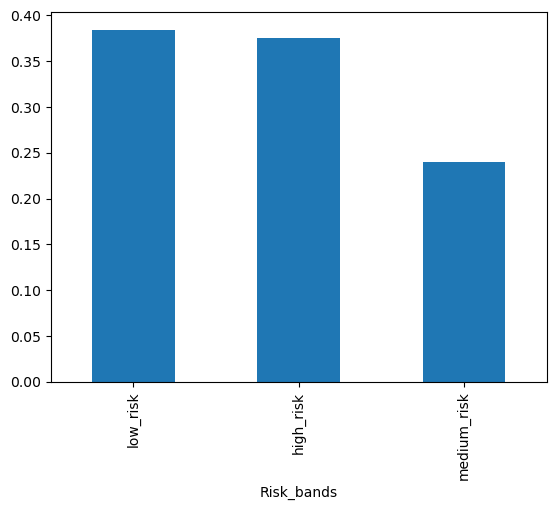

In [57]:
labels = ['low_risk' , 'medium_risk' , 'high_risk']
bins = [0 , cost_efficient_threshold * 0.5 , cost_efficient_threshold , 1.0] 

df_enriched['Risk_bands'] = pd.cut(df_enriched['Attrition_Risk'],bins,labels=labels,right = False) 
df_enriched['Risk_bands'].value_counts(normalize = True).plot(kind = 'bar');

In [58]:
standardized_OR

,Feature,Coefficient,Odds Ratio
26,MaritalStatus_Single,0.699622,2.012992
10,OverTime,0.677665,1.969273
18,JobRole_Laboratory Technician,0.517405,1.677668
16,YearsSinceLastPromotion,0.483890,1.622373
23,JobRole_Sales Executive,0.451926,1.571336
24,JobRole_Sales Representative,0.444908,1.560347
1,BusinessTravel,0.406829,1.502047
25,MaritalStatus_Married,0.361074,1.434869
9,NumCompaniesWorked,0.353736,1.424379
17,JobRole_Human Resources,0.341788,1.407462


### 5.3 Profiling high-risk employees

In [59]:
#define identified top drivers and protectors of attrition and seggregate them as their data type. (only choosing a few that provides actionable or ethical profiling features)
num_features = ['Age', 'EnvironmentSatisfaction' , 'MonthlyIncome' , 'TrainingTimesLastYear' ]
num_profile = df_enriched.groupby('Risk_bands' , observed = False)[num_features].mean().T



#distribution proportion of the categorical variables' key attrition target values.
cat_metrics = {'OverTime' : 'Yes',
             'BusinessTravel' : 'Travel_Frequently'}

cat_rows = {}
for col,target in cat_metrics.items():    
     cat_rows[f'{col}-({target})'] = df_enriched.groupby('Risk_bands' , observed = True)[col].apply(lambda x:(x == target).mean().round(4)*100)
cat_profile = pd.DataFrame(cat_rows).T

attrition_profile = pd.concat([num_profile , cat_profile])
attrition_profile = attrition_profile.drop(columns = 'medium_risk', ).rename_axis('Features')

attrition_profile['Variance(%)'] = (((attrition_profile['high_risk'] - attrition_profile['low_risk']) / attrition_profile['low_risk'])*100)
print(attrition_profile)


Risk_bands                             low_risk    high_risk  Variance(%)
Features                                                                 
Age                                   39.433628    34.809783   -11.725641
EnvironmentSatisfaction                2.906195     2.454710   -15.535248
MonthlyIncome                       8482.371681  4835.228261   -42.996741
TrainingTimesLastYear                  2.989381     2.612319   -12.613372
OverTime-(Yes)                        11.680000    46.740000   300.171233
BusinessTravel-(Travel_Frequently)    11.150000    27.360000   145.381166


#### Model Coefs(UnStd) for identified high risk employee's features.

In [60]:
#proving the previous section with statistical inference from the model output using odds ratio. 
unstandardized_OR[unstandardized_OR['Features'].isin(['Age', 'EnvironmentSatisfaction', 'MonthlyIncome', 'TrainingTimesLastYear', 'OverTime','BusinessTravel'])]

,Features,Unstd_Coef,Unstd_Odds_ratio
0,Age,-0.022397,0.977852
1,BusinessTravel,0.763196,2.145121
4,EnvironmentSatisfaction,-0.394352,0.674117
8,MonthlyIncome,-0.000038,0.999962
10,OverTime,1.533362,4.633728
14,TrainingTimesLastYear,-0.175099,0.839374


**Insights:**

**Primary Risk Catalysts**
- **OverTime** (300.17% Variance) - Almost half of the high risk employees work overtime compared to the only 11.6% of the low risk employees, a difference of roughly 37.5 percentage points. this severe operational overwork is a key trigger for employee attrition.
- **BusinessTravel** (145.38% Variance) - 1.4 times more high risk employees travel frequently compared to the baseline, employee burnout from frequent travel fatigue contributes to turnover.

**Compensation and Age**
- **MonthlyIncome** (-42.99 Variance) - Severe pay deficit among high risk staff; earning an average of 4835.22 versus low risk staff, 8428.37 per month.
- **Age** (-11.72 Variance) -  High-risk staff skew younger (34.8 vs. 39.4 years old), placing them in an active, market-mobile career stage where pay gaps drive quick resignations.

**Workplace and learning deficit**
- **EnvironmentSatisfaction** (-15.53 Variance) -  work environment satisfaction drops from 2.90 to 2.45 out of 4, portraying that daily friction and comfortability accelarates exit intent.
- **TrainingTimesLastYear** (-12.61 Variance) - missed trainings / participations leading towards plateauing development.

**Persona Profiles**
- **Low-Risk Anchor:** Late-30s established professional earning market-rate compensation (8.4k / month), working standard hours (89% non-overtime), with high workplace satisfaction and routine upskilling.
- **High-Risk Persona:** Mid-30s mid-level worker facing compensation compression (4.7k/month), severe workload stress (46% overtime; 27% heavy travel), and lower engagement, making them prime targets for external recruitment.

### 5.4 Cost and Savings effect

**Assumptions :**
- Have made a more naieve assumption that all intervention are successful.
- Cost performance not scaled towards total work force, rather compute test data cost effects

**Pre-defined logic during threshold analysis earlier**
1. status_quo -> all positive class implies attrition_cost. y_true x attritoin_cost
2. model_cost -> tp x intervention_cost + fp x intervention_cost + fn x attrition_cost

In [61]:
pct_cost_reduction = ((status_quo_cost - post_model_cost) / status_quo_cost)*100
print('COST EFFECT OF THE MODEL ON THE TEST DATA')
print('='*50)
print(f'STATUS QUO COST  : ${status_quo_cost:,.2f}')
print(f'MODEL BASED COST : ${post_model_cost:,.2f} USD')
print(f'NET SAVINGS      : ${status_quo_cost - post_model_cost:,.2f} USD')
print(f'NET SAVINGS(%)   : {pct_cost_reduction:.2f}%')


COST EFFECT OF THE MODEL ON THE TEST DATA
STATUS QUO COST  : $253,000.00
MODEL BASED COST : $139,100.00 USD
NET SAVINGS      : $113,900.00 USD
NET SAVINGS(%)   : 45.02%


## 6. Power BI Dashboard Insights (rough)

In [68]:
df_enriched['Action_Required'] = np.where(df_enriched['Predicted_Attrition'] == 1 , 'Intervention Required' , 'Routine Monitoring')

dept_segment = pd.crosstab(df_enriched['Department'],df_enriched['Risk_bands'] , normalize = 'index') # proportion of contribution by departments to each risk level
travel_segment = pd.crosstab(df_enriched['BusinessTravel'], df_enriched['Risk_bands'], normalize = 'index') #risk proportion among each level of travel
dept_segment

Risk_bands,low_risk,medium_risk,high_risk
Department,,,
Human Resources,0.222222,0.206349,0.571429
Research & Development,0.430801,0.252862,0.316337
Sales,0.307175,0.217489,0.475336


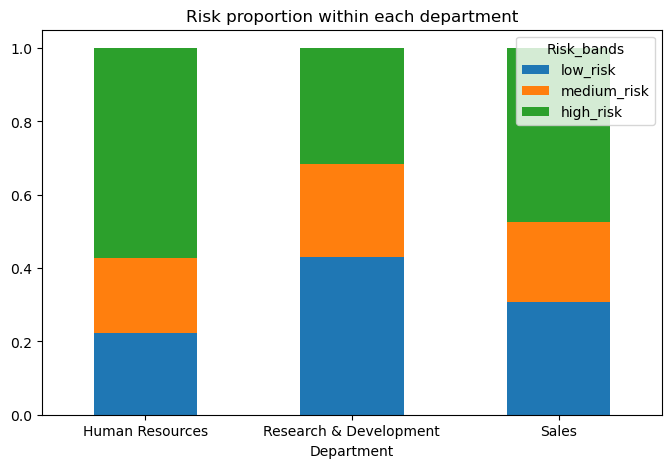

In [71]:
fig,ax = plt.subplots(figsize = (8,5))
dept_segment.plot(kind = 'bar' , stacked = True, ax=ax )
ax.set_title('Risk proportion within each department')
ax.set_xlabel('Department')
ax.tick_params(rotation = 0)

In [67]:
#export the enriched dataset with the new insight model prediction based variables.
df_enriched.to_csv('hr_attrition_enriched.csv' , index = False)
import os
print(os.getcwd())

/Users/arjunkumar/Projects/IBM Project


## 6. Summary & Recommendation

**Problem:**
- Employee attrition is heavily concentrated among younger, overworked, and undercompensated mid-level staff. Baseline unmitigated turnover costs the organization $253,000 on holdout evaluation data alone, driven primarily by burnout, travel fatigue, and severe compensation compression.

**Approach:**
- Developed an interpretable risk-scoring model combined with financial threshold optimization (t = 0.45). By mapping model outputs directly to level-specific intervention costs and replacement expenses, the pipeline targets retention resources strictly where financial ROI is maximized.

**Key Findings:**
- Financial Impact: Deploying the model-driven strategy reduces total turnover expenditures from 253,000 to 139,100, achieving a 45.02% net cost reduction ($113,900 net savings).
- Primary Risk Drivers: Overtime is the single largest operational catalyst—high-risk employees are 4.6x more likely to work overtime (49.39% vs 11.88%). Frequent business travel increases attrition odds by 2.14x 28.28% vs 11.55%
- Compensation Gap: High-risk personnel face a 42.67% monthly pay deficit (4,741/month vs 8,270/month baseline), making them highly susceptible to external recruitment.
  
**Recommendation:**
- Targeted Overtime Caps: Mandate workload reviews for staff logging consistent overtime, as workload stress represents the single highest operational flight risk.
- Selective Pay Adjustment: Allocate intervention budgets toward recalibrating salary compression for mid-30s employees in high-demand roles before they reach exit intent.
- Deployment Strategy: Operationalize the $0.45$ probability threshold in HR systems to automatically trigger proactive retention interventions for flagged high-risk staff.

## Key things to remember next time (Notes for self)

- Much elaborate feature engineering shouldve been done post EDA for better interpretation and value from the combination of features.
- Wouldve been good to include PCA for further analysis and feature engineering on correlated features.
- Shouldve done VIF pruning prior to modelling
- didnt check pvalues to look out for statistical significance of each variables using stats models.
- StagnationRatio acts as a proxy for company tenure and employee age rather than true promotional dissatisfaction. This introduces severe confounding bias, generating a false inverse relationship with turnover that risks prompting harmful HR policy recommendations.
- while calculating predicted net savings by using the model, it is assumed that 100% of the intervention is successful, which is a naieve assumption. it is implemented knowing that not all intervention is successful in reality for simplicity
- for model selection , using just an untuned random forest model and logistic regression model is not the best way to identify on which model is actually better to use, shouldve done cross validation on training set itself to find the better scores. with implemented parameters for each of the models to find out which one was indeed more efficient to move on with. 